In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Set visualization style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.facecolor'] = 'white'

## Load Dataset

In [2]:
# Load the dataset
df = pd.read_csv('Crime_Incidents_-_2025.csv')

# Parse datetime columns
df['REPORT_DAT'] = pd.to_datetime(df['REPORT_DAT'], utc=True)
df['START_DATE'] = pd.to_datetime(df['START_DATE'], utc=True)
df['END_DATE'] = pd.to_datetime(df['END_DATE'], utc=True, errors='coerce')

print(f"Dataset loaded successfully!")
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")

Dataset loaded successfully!
Shape: 24148 rows, 25 columns


In [3]:
#from google.colab import drive
#drive.mount('/content/drive')

---
# Question 1: Data Dictionary

**What do the features mean and what is the type of data?**

The dataset contains 25 variables that can be categorized into:
- **Geographic (6):** X, Y, XBLOCK, YBLOCK, LATITUDE, LONGITUDE
- **Administrative (9):** WARD, ANC, DISTRICT, PSA, NEIGHBORHOOD_CLUSTER, BLOCK_GROUP, CENSUS_TRACT, VOTING_PRECINCT, BID
- **Temporal (4):** REPORT_DAT, START_DATE, END_DATE, SHIFT
- **Crime Details (3):** OFFENSE, METHOD, BLOCK
- **Identifiers (3):** CCN, OBJECTID, OCTO_RECORD_ID

In [4]:
# Display column names and data types
print("Column Names and Data Types:")
print("="*50)
print(df.dtypes)

Column Names and Data Types:
X                                   float64
Y                                   float64
CCN                                   int64
REPORT_DAT              datetime64[ns, UTC]
START_DATE              datetime64[ns, UTC]
END_DATE                datetime64[ns, UTC]
BLOCK                                object
OFFENSE                              object
METHOD                               object
SHIFT                                object
WARD                                  int64
ANC                                  object
DISTRICT                            float64
PSA                                 float64
NEIGHBORHOOD_CLUSTER                 object
BLOCK_GROUP                          object
CENSUS_TRACT                        float64
VOTING_PRECINCT                      object
BID                                  object
XBLOCK                              float64
YBLOCK                              float64
LATITUDE                            float64
LON

In [5]:
# Create Data Dictionary DataFrame
data_dict = pd.DataFrame({
    'Variable': df.columns,
    'Data_Type': df.dtypes.astype(str).values,
    'Non_Null': df.count().values,
    'Null_Count': df.isnull().sum().values
})
print("\nData Dictionary:")
data_dict


Data Dictionary:


,Variable,Data_Type,Non_Null,Null_Count
0,X,float64,24148,0
1,Y,float64,24148,0
2,CCN,int64,24148,0
3,REPORT_DAT,"datetime64[ns, UTC]",24148,0
4,START_DATE,"datetime64[ns, UTC]",24148,0
5,END_DATE,"datetime64[ns, UTC]",22457,1691
6,BLOCK,object,24148,0
7,OFFENSE,object,24148,0
8,METHOD,object,24148,0
9,SHIFT,object,24148,0


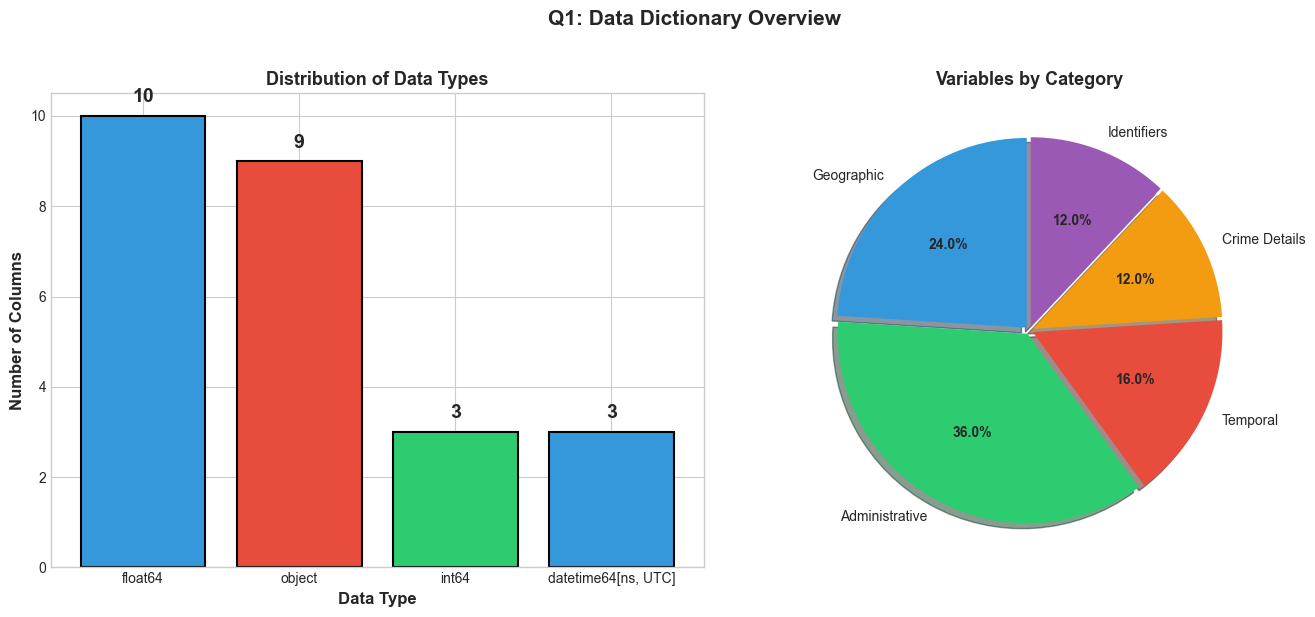

In [6]:
# Q1 Visualization: Data Types and Variable Categories
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: Data Types Distribution
dtype_counts = df.dtypes.astype(str).value_counts()
colors1 = ['#3498db', '#e74c3c', '#2ecc71']
bars = axes[0].bar(dtype_counts.index, dtype_counts.values, color=colors1, edgecolor='black', linewidth=1.5)
axes[0].set_xlabel('Data Type', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Columns', fontsize=12, fontweight='bold')
axes[0].set_title('Distribution of Data Types', fontsize=13, fontweight='bold')
for bar, val in zip(bars, dtype_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 0.3, str(val), ha='center', fontsize=14, fontweight='bold')

# Right: Variable Categories
categories = {'Geographic': 6, 'Administrative': 9, 'Temporal': 4, 'Crime Details': 3, 'Identifiers': 3}
colors2 = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12', '#9b59b6']
wedges, texts, autotexts = axes[1].pie(categories.values(), labels=categories.keys(), autopct='%1.1f%%',
                                        colors=colors2, explode=(0.02,)*5, shadow=True, startangle=90)
for autotext in autotexts:
    autotext.set_fontweight('bold')
axes[1].set_title('Variables by Category', fontsize=13, fontweight='bold')

plt.suptitle('Q1: Data Dictionary Overview', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('Q1_data_dictionary.png', dpi=150, bbox_inches='tight')
plt.show()

---
# Question 2: Use-Case / Business Problem

**What is your use-case trying to solve?**

**Problem Statement:** How can we identify patterns in crime occurrence across time, location, and crime type to enable effective resource allocation and predict future crime hotspots?

**Key Objectives:**
1. **Temporal Analysis** - Identify when crimes occur (hour, day, season)
2. **Geographic Analysis** - Find crime hotspots by ward and neighborhood
3. **Crime Type Analysis** - Understand offense distribution and methods
4. **Predictive Foundation** - Build clean dataset for future modeling

**Stakeholders:**
- **Law Enforcement:** Optimize patrol routes and resource allocation
- **City Government:** Inform policy decisions and investments
- **Community Organizations:** Develop safety initiatives
- **Residents:** Make informed decisions about personal safety

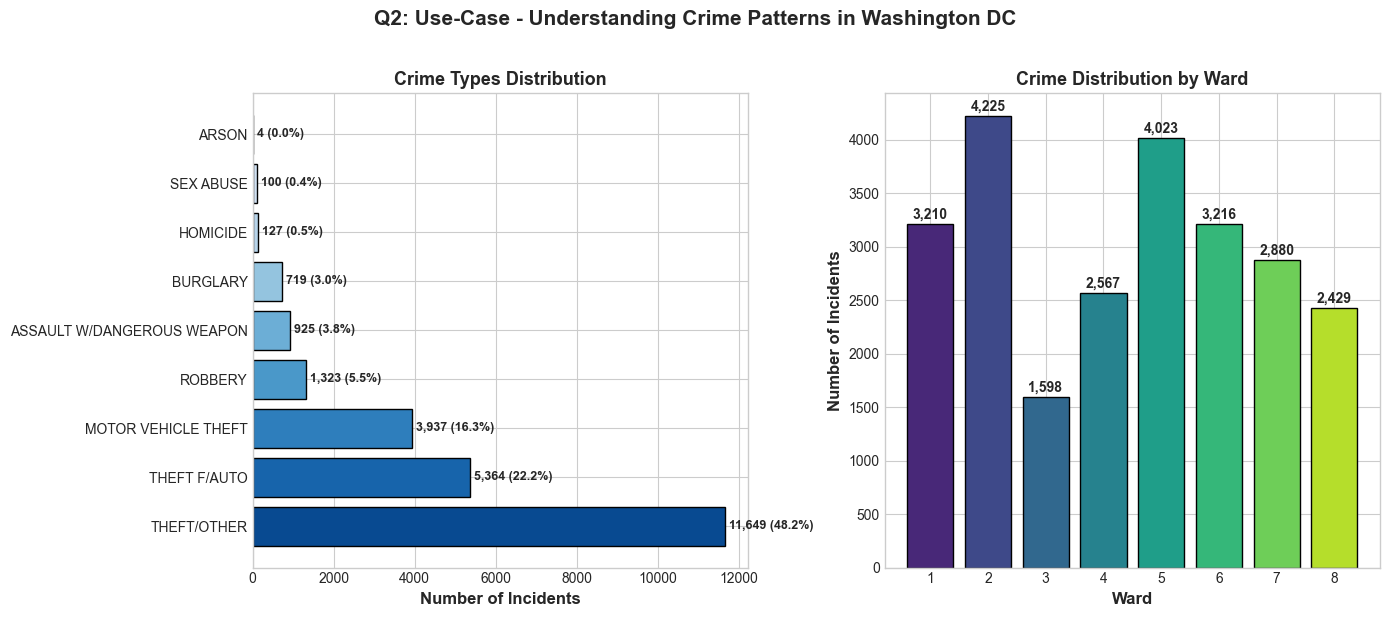


Key Findings:
- THEFT/OTHER is the most common crime: 11,649 incidents (48.2%)
- Ward 2 has the highest crime count: 4,225 incidents
- Ward 3 has the lowest crime count: 1,598 incidents


In [7]:
# Q2 Visualization: Crime Distribution - Understanding the Problem
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: Crime Types
offense_counts = df['OFFENSE'].value_counts()
colors = sns.color_palette("Blues_r", len(offense_counts))
bars = axes[0].barh(offense_counts.index, offense_counts.values, color=colors, edgecolor='black')
axes[0].set_xlabel('Number of Incidents', fontsize=12, fontweight='bold')
axes[0].set_title('Crime Types Distribution', fontsize=13, fontweight='bold')
total = offense_counts.sum()
for bar, val in zip(bars, offense_counts.values):
    axes[0].text(val + 100, bar.get_y() + bar.get_height()/2, f'{val:,} ({val/total*100:.1f}%)',
                 va='center', fontsize=9, fontweight='bold')

# Right: By Ward
ward_counts = df['WARD'].value_counts().sort_index()
colors_ward = sns.color_palette("viridis", len(ward_counts))
bars2 = axes[1].bar(ward_counts.index.astype(str), ward_counts.values, color=colors_ward, edgecolor='black')
axes[1].set_xlabel('Ward', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Number of Incidents', fontsize=12, fontweight='bold')
axes[1].set_title('Crime Distribution by Ward', fontsize=13, fontweight='bold')
for bar, val in zip(bars2, ward_counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 50, f'{val:,}', ha='center', fontsize=10, fontweight='bold')

plt.suptitle('Q2: Use-Case - Understanding Crime Patterns in Washington DC', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('Q2_usecase.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"\nKey Findings:")
print(f"- THEFT/OTHER is the most common crime: {offense_counts.iloc[0]:,} incidents ({offense_counts.iloc[0]/total*100:.1f}%)")
print(f"- Ward 2 has the highest crime count: {ward_counts.max():,} incidents")
print(f"- Ward 3 has the lowest crime count: {ward_counts.min():,} incidents")

---
# Question 3: Data Exploration

**What did you do with the data in the context of exploration?**

The following exploration activities were performed:
1. Examined categorical variables (OFFENSE, METHOD, SHIFT, WARD)
2. Analyzed temporal patterns (monthly trends)
3. Computed descriptive statistics for numeric variables
4. Identified value distributions across key features

In [8]:
# Descriptive Statistics
print("Descriptive Statistics for Numeric Variables:")
print("="*60)
print(df.describe())

Descriptive Statistics for Numeric Variables:
                   X              Y           CCN          WARD      DISTRICT  \
count   24148.000000   24148.000000  2.414800e+04  24148.000000  24116.000000   
mean   399154.682594  137966.788524  2.512723e+07      4.378209      3.648781   
std      3024.914228    3473.558385  4.617018e+05      2.280718      1.832224   
min    390294.800000  127142.290000  5.131706e+06      1.000000      1.000000   
25%    397204.160000  136464.507500  2.505102e+07      2.000000      2.000000   
50%    398817.030000  137862.110000  2.510260e+07      5.000000      3.000000   
75%    400973.515000  139967.520000  2.515881e+07      6.000000      5.000000   
max    407806.750900  147365.030000  8.927285e+07      8.000000      7.000000   

                PSA   CENSUS_TRACT         XBLOCK         YBLOCK  \
count  24116.000000   24142.000000   24148.000000   24148.000000   
mean     369.479806    7589.065902  399154.682594  137966.788524   
std      182.852950 

In [9]:
# Categorical Variable Analysis
print("\nOFFENSE Distribution:")
print(df['OFFENSE'].value_counts())

print("\nMETHOD Distribution:")
print(df['METHOD'].value_counts())

print("\nSHIFT Distribution:")
print(df['SHIFT'].value_counts())


OFFENSE Distribution:
OFFENSE
THEFT/OTHER                   11649
THEFT F/AUTO                   5364
MOTOR VEHICLE THEFT            3937
ROBBERY                        1323
ASSAULT W/DANGEROUS WEAPON      925
BURGLARY                        719
HOMICIDE                        127
SEX ABUSE                       100
ARSON                             4
Name: count, dtype: int64

METHOD Distribution:
METHOD
OTHERS    22465
GUN        1292
KNIFE       391
Name: count, dtype: int64

SHIFT Distribution:
SHIFT
EVENING     10055
DAY          9954
MIDNIGHT     4139
Name: count, dtype: int64


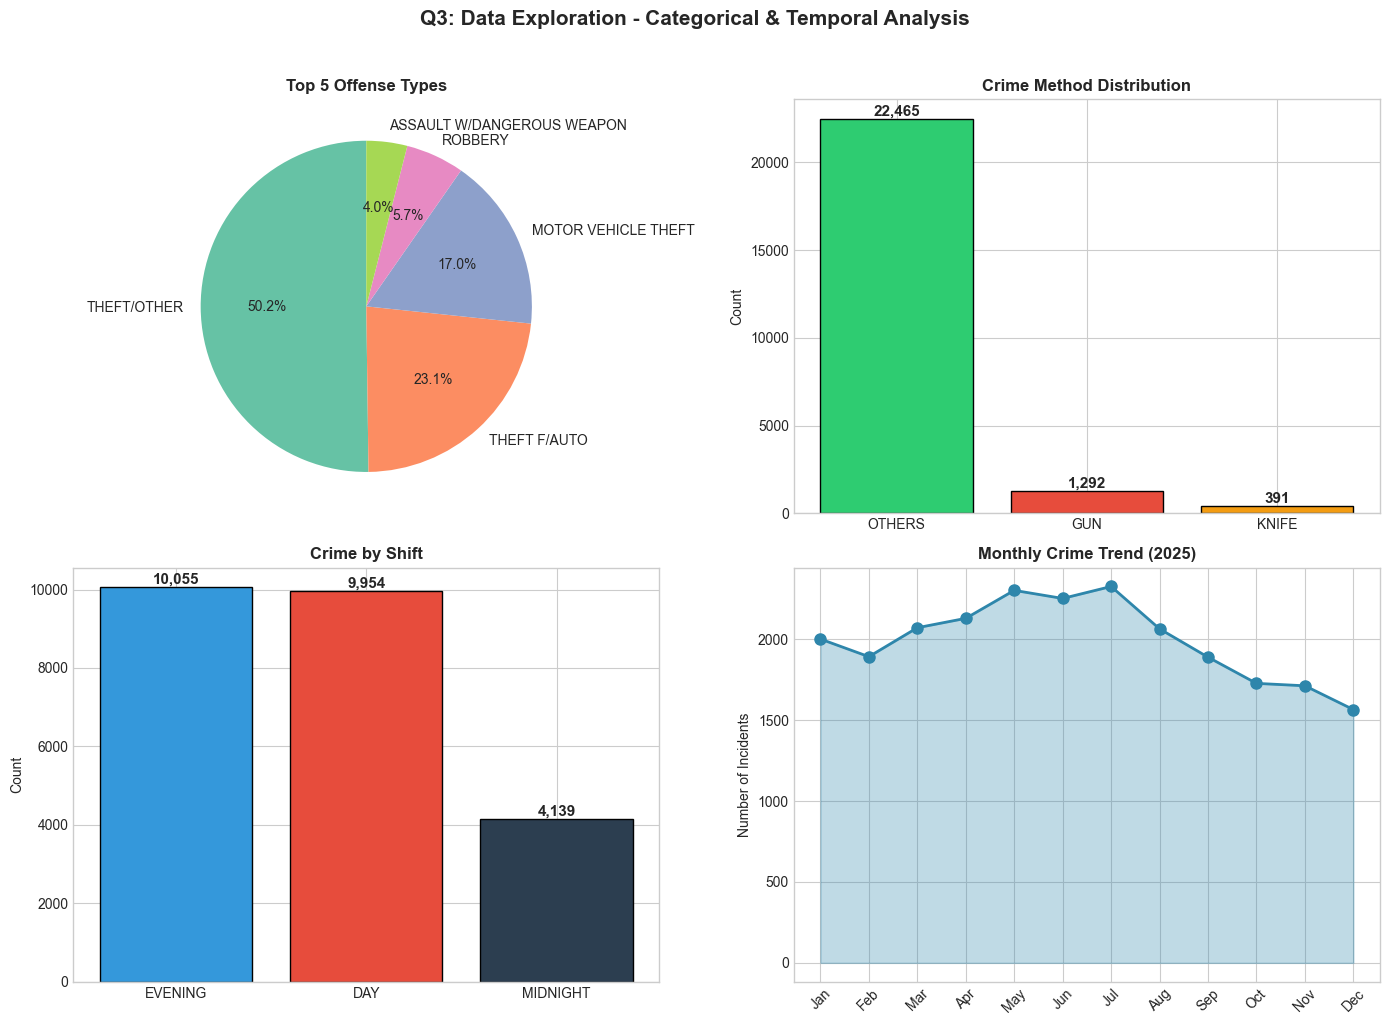

In [10]:
# Q3 Visualization: Categorical & Temporal Analysis
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Top 5 Offense Types Pie
offense_counts = df['OFFENSE'].value_counts()
colors1 = sns.color_palette("Set2", 5)
axes[0,0].pie(offense_counts.values[:5], labels=offense_counts.index[:5], autopct='%1.1f%%',
              colors=colors1, startangle=90)
axes[0,0].set_title('Top 5 Offense Types', fontsize=12, fontweight='bold')

# Method Distribution
method_counts = df['METHOD'].value_counts()
colors2 = ['#2ecc71', '#e74c3c', '#f39c12']
bars = axes[0,1].bar(method_counts.index, method_counts.values, color=colors2, edgecolor='black')
axes[0,1].set_title('Crime Method Distribution', fontsize=12, fontweight='bold')
axes[0,1].set_ylabel('Count')
for bar, val in zip(bars, method_counts.values):
    axes[0,1].text(bar.get_x() + bar.get_width()/2, val + 200, f'{val:,}', ha='center', fontsize=11, fontweight='bold')

# Shift Distribution
shift_counts = df['SHIFT'].value_counts()
colors3 = ['#3498db', '#e74c3c', '#2c3e50']
bars2 = axes[1,0].bar(shift_counts.index, shift_counts.values, color=colors3, edgecolor='black')
axes[1,0].set_title('Crime by Shift', fontsize=12, fontweight='bold')
axes[1,0].set_ylabel('Count')
for bar, val in zip(bars2, shift_counts.values):
    axes[1,0].text(bar.get_x() + bar.get_width()/2, val + 100, f'{val:,}', ha='center', fontsize=11, fontweight='bold')

# Monthly Trend
df_2025 = df[df['START_DATE'].dt.year == 2025].copy()
df_2025['MONTH'] = df_2025['START_DATE'].dt.month
month_counts = df_2025['MONTH'].value_counts().sort_index()
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
axes[1,1].plot(month_names, month_counts.values, marker='o', linewidth=2, markersize=8, color='#2E86AB')
axes[1,1].fill_between(month_names, month_counts.values, alpha=0.3, color='#2E86AB')
axes[1,1].set_title('Monthly Crime Trend (2025)', fontsize=12, fontweight='bold')
axes[1,1].set_ylabel('Number of Incidents')
axes[1,1].tick_params(axis='x', rotation=45)

plt.suptitle('Q3: Data Exploration - Categorical & Temporal Analysis', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('Q3_exploration.png', dpi=150, bbox_inches='tight')
plt.show()

---
# Question 4: Dataset Size

**How many entries are in the dataset?**

In [11]:
# Dataset Size Summary
print("Dataset Size Summary")
print("="*50)
print(f"Total Records (Rows):     {df.shape[0]:,}")
print(f"Total Features (Columns): {df.shape[1]}")
print(f"Total Data Points:        {df.shape[0] * df.shape[1]:,}")
print(f"\n2025 Records:             {len(df[df['START_DATE'].dt.year == 2025]):,}")
print(f"2024 Records:             {len(df[df['START_DATE'].dt.year == 2024]):,}")
print(f"Pre-2024 Records:         {len(df[df['START_DATE'].dt.year < 2024]):,}")
print(f"2026 Records:             {len(df[df['START_DATE'].dt.year > 2025]):,}")

Dataset Size Summary
Total Records (Rows):     24,148
Total Features (Columns): 25
Total Data Points:        603,700

2025 Records:             23,942
2024 Records:             188
Pre-2024 Records:         15
2026 Records:             3


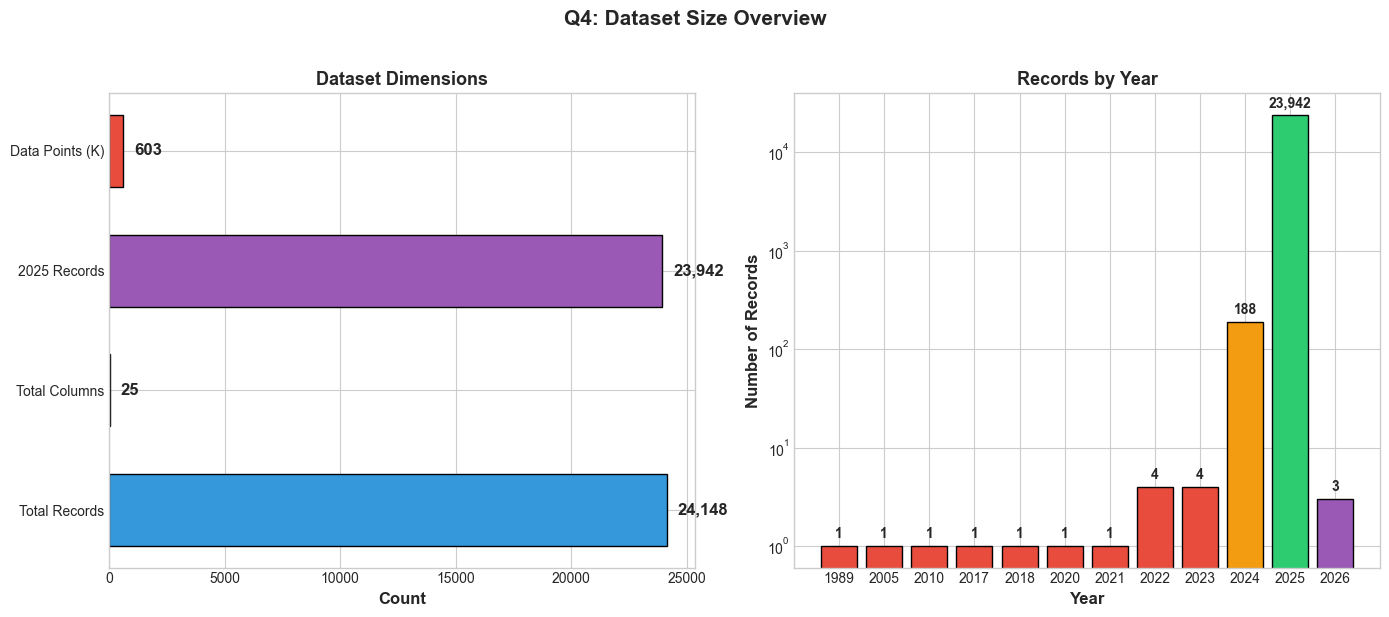

In [12]:
# Q4 Visualization: Dataset Size
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: Size metrics
metrics = ['Total Records', 'Total Columns', '2025 Records', 'Data Points (K)']
values = [df.shape[0], df.shape[1], len(df[df['START_DATE'].dt.year == 2025]), df.shape[0]*df.shape[1]/1000]
colors = ['#3498db', '#2ecc71', '#9b59b6', '#e74c3c']
bars = axes[0].barh(metrics, values, color=colors, edgecolor='black', height=0.6)
axes[0].set_xlabel('Count', fontsize=12, fontweight='bold')
axes[0].set_title('Dataset Dimensions', fontsize=13, fontweight='bold')
for bar, val in zip(bars, values):
    display_val = f'{int(val):,}' if val > 100 else f'{val:.0f}'
    axes[0].text(val + max(values)*0.02, bar.get_y() + bar.get_height()/2, display_val,
                 va='center', fontsize=12, fontweight='bold')

# Right: Records by year
year_counts = df['START_DATE'].dt.year.value_counts().sort_index()
year_labels = [str(y) for y in year_counts.index]
colors_year = ['#e74c3c' if y < 2024 else '#f39c12' if y == 2024 else '#2ecc71' if y == 2025 else '#9b59b6'
               for y in year_counts.index]
bars2 = axes[1].bar(year_labels, year_counts.values, color=colors_year, edgecolor='black')
axes[1].set_xlabel('Year', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Number of Records', fontsize=12, fontweight='bold')
axes[1].set_title('Records by Year', fontsize=13, fontweight='bold')
axes[1].set_yscale('log')
for bar, val in zip(bars2, year_counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val * 1.2, f'{val:,}', ha='center', fontsize=10, fontweight='bold')

plt.suptitle('Q4: Dataset Size Overview', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('Q4_dataset_size.png', dpi=150, bbox_inches='tight')
plt.show()

---
# Question 5: Data Quality Assessment

**Was there missing data? Duplications? How clean was the data?**

In [13]:
# Missing Values Analysis
print("Missing Values Analysis")
print("="*60)
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({
    'Missing_Count': missing,
    'Missing_Percentage': missing_pct
}).sort_values('Missing_Count', ascending=False)
print(missing_df[missing_df['Missing_Count'] > 0])

Missing Values Analysis
                Missing_Count  Missing_Percentage
OCTO_RECORD_ID          24148              100.00
BID                     19342               80.10
END_DATE                 1691                7.00
PSA                        32                0.13
DISTRICT                   32                0.13
BLOCK_GROUP                 6                0.02
CENSUS_TRACT                6                0.02


In [14]:
# Duplicate Analysis
print("\nDuplicate Records Analysis")
print("="*60)
print(f"Duplicate Rows:       {df.duplicated().sum()}")
print(f"Duplicate CCN Values: {df['CCN'].duplicated().sum()}")


Duplicate Records Analysis
Duplicate Rows:       0
Duplicate CCN Values: 3


In [15]:
# Data Quality Metrics
print("\nData Quality Summary")
print("="*60)
total_cells = df.shape[0] * df.shape[1]
missing_cells = df.isnull().sum().sum()
completeness = ((total_cells - missing_cells) / total_cells * 100)

print(f"Total Data Points:    {total_cells:,}")
print(f"Missing Data Points:  {missing_cells:,}")
print(f"Data Completeness:    {completeness:.2f}%")

# Temporal anomalies
df['REPORT_LAG'] = (df['REPORT_DAT'] - df['START_DATE']).dt.days
print(f"\nTemporal Anomalies:")
print(f"- Negative reporting lag: {(df['REPORT_LAG'] < 0).sum()}")
print(f"- Extreme lag (>365 days): {(df['REPORT_LAG'] > 365).sum()}")
print(f"- Pre-2024 records: {(df['START_DATE'].dt.year < 2024).sum()}")
print(f"- 2026 records (errors): {(df['START_DATE'].dt.year > 2025).sum()}")


Data Quality Summary
Total Data Points:    603,700
Missing Data Points:  45,257
Data Completeness:    92.50%

Temporal Anomalies:
- Negative reporting lag: 108
- Extreme lag (>365 days): 23
- Pre-2024 records: 15
- 2026 records (errors): 3


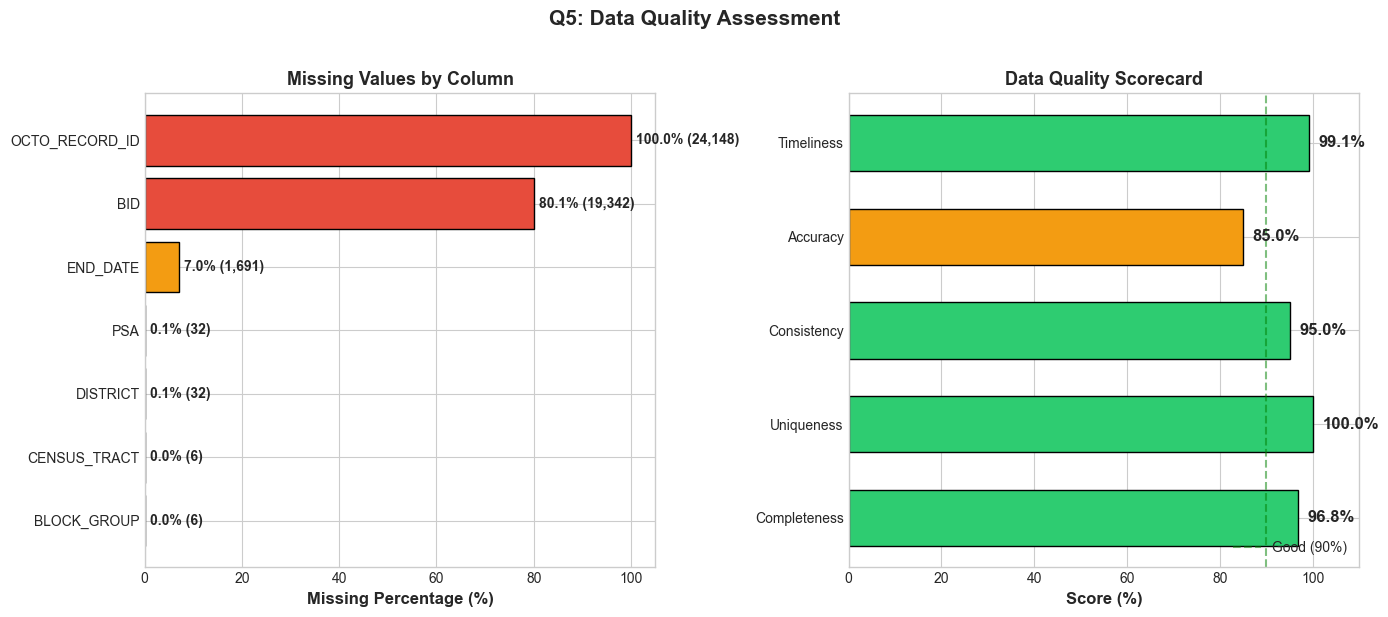

In [16]:
# Q5 Visualization: Data Quality
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: Missing values
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=True)
missing_pct = (missing / len(df) * 100)
colors = ['#e74c3c' if pct > 50 else '#f39c12' if pct > 5 else '#2ecc71' for pct in missing_pct]

bars = axes[0].barh(missing.index, missing_pct.values, color=colors, edgecolor='black')
axes[0].set_xlabel('Missing Percentage (%)', fontsize=12, fontweight='bold')
axes[0].set_title('Missing Values by Column', fontsize=13, fontweight='bold')
for bar, pct, cnt in zip(bars, missing_pct.values, missing.values):
    axes[0].text(pct + 1, bar.get_y() + bar.get_height()/2, f'{pct:.1f}% ({cnt:,})',
                 va='center', fontsize=10, fontweight='bold')

# Right: Quality scorecard
quality_dims = ['Completeness', 'Uniqueness', 'Consistency', 'Accuracy', 'Timeliness']
quality_scores = [96.8, 100, 95, 85, 99.1]
colors_qual = ['#2ecc71' if s >= 90 else '#f39c12' if s >= 70 else '#e74c3c' for s in quality_scores]

bars2 = axes[1].barh(quality_dims, quality_scores, color=colors_qual, edgecolor='black', height=0.6)
axes[1].set_xlabel('Score (%)', fontsize=12, fontweight='bold')
axes[1].set_title('Data Quality Scorecard', fontsize=13, fontweight='bold')
axes[1].set_xlim(0, 110)
for bar, score in zip(bars2, quality_scores):
    axes[1].text(score + 2, bar.get_y() + bar.get_height()/2, f'{score:.1f}%',
                 va='center', fontsize=12, fontweight='bold')
axes[1].axvline(x=90, color='green', linestyle='--', alpha=0.5, label='Good (90%)')
axes[1].legend(loc='lower right')

plt.suptitle('Q5: Data Quality Assessment', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('Q5_data_quality.png', dpi=150, bbox_inches='tight')
plt.show()

---
# Summary

| Question | Key Findings |
|----------|-------------|
| **Q1: Data Dictionary** | 25 variables: Geographic (6), Administrative (9), Temporal (4), Crime Details (3), Identifiers (3) |
| **Q2: Use-Case** | Crime pattern analysis to support public safety decisions through temporal, geographic, and crime type analysis |
| **Q3: Exploration** | THEFT/OTHER dominates (48.2%), EVENING shift has most crimes (41.6%), July has highest crime count |
| **Q4: Dataset Size** | 24,148 records, 25 features, 99.1% from 2025 |
| **Q5: Data Quality** | 96.8% completeness, 0 duplicate rows, 1 fully null column (OCTO_RECORD_ID), minor temporal anomalies |



## Q6: Outliers or Suspicious Data

Several checks were performed to identify outliers and suspicious records that could impact the reliability of the analysis.

The following categories of anomalies were evaluated:

- **Temporal anomalies**
  - Negative reporting lag where the report date occurs before the incident start date
  - Extremely large reporting delays, indicating late or historical data entry
  - Negative event duration where the end date precedes the start date
  - Unusually long event durations that may indicate data entry errors

- **Scope-related anomalies**
  - Records with incident dates outside the target analysis year (2025)

- **Geographic anomalies** (when latitude and longitude are available)
  - Coordinates that fall outside a reasonable geographic boundary for Washington, DC

Identifying these issues is critical because such records can distort time-based trends, spatial hotspot analysis, and summary statistics.


In [17]:
# Create anomaly features
df["REPORT_LAG_DAYS"] = (df["REPORT_DAT"] - df["START_DATE"]).dt.total_seconds() / 86400.0
df["EVENT_DURATION_HRS"] = (df["END_DATE"] - df["START_DATE"]).dt.total_seconds() / 3600.0

# Suspicious Flags
df["FLAG_NEG_REPORT_LAG"] = df["REPORT_LAG_DAYS"] < 0
df["FLAG_EXTREME_REPORT_LAG_365D"] = df["REPORT_LAG_DAYS"] > 365

df["FLAG_NEG_DURATION"] = df["EVENT_DURATION_HRS"] < 0
df["FLAG_EXTREME_DURATION_30D"] = df["EVENT_DURATION_HRS"] > (30*24)

df["START_YEAR"] = df["START_DATE"].dt.year
df["FLAG_NOT_2025"] = df["START_YEAR"] != 2025

# ---------- Flag Summary ----------
flag_cols = [c for c in df.columns if c.startswith("FLAG_")]
flag_summary = pd.DataFrame({
    "Flag": flag_cols,
    "Count": [df[c].sum() for c in flag_cols],
    "Percent": [df[c].mean()*100 for c in flag_cols]
}).sort_values("Count", ascending=False)

flag_summary


,Flag,Count,Percent
4,FLAG_NOT_2025,206,0.853073
3,FLAG_EXTREME_DURATION_30D,140,0.579758
0,FLAG_NEG_REPORT_LAG,108,0.447242
1,FLAG_EXTREME_REPORT_LAG_365D,23,0.095246
2,FLAG_NEG_DURATION,1,0.004141


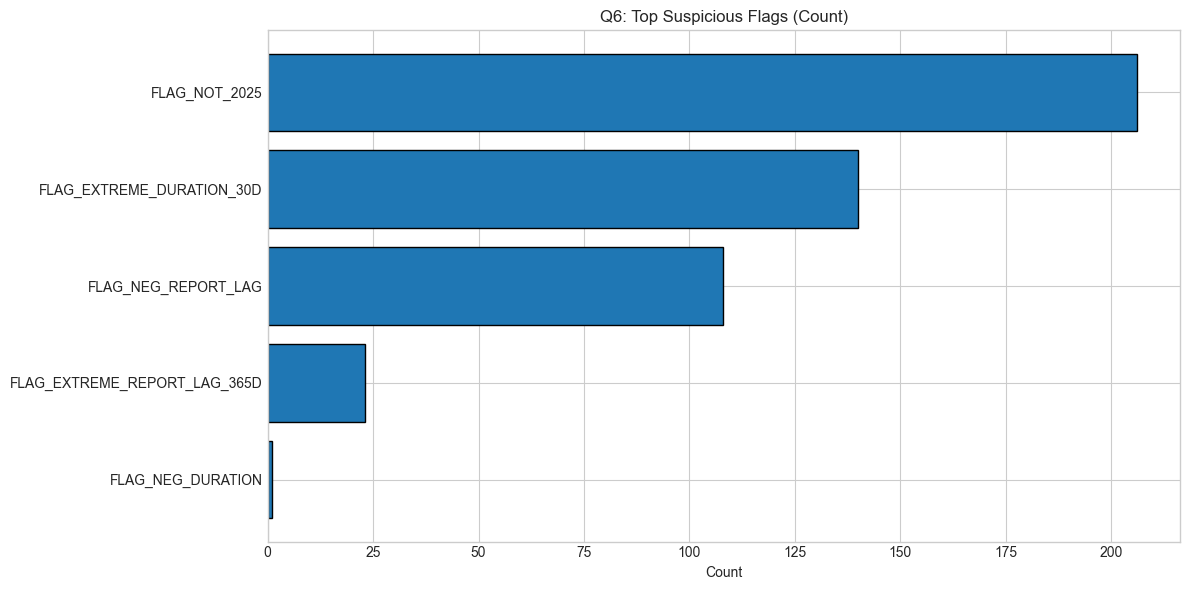

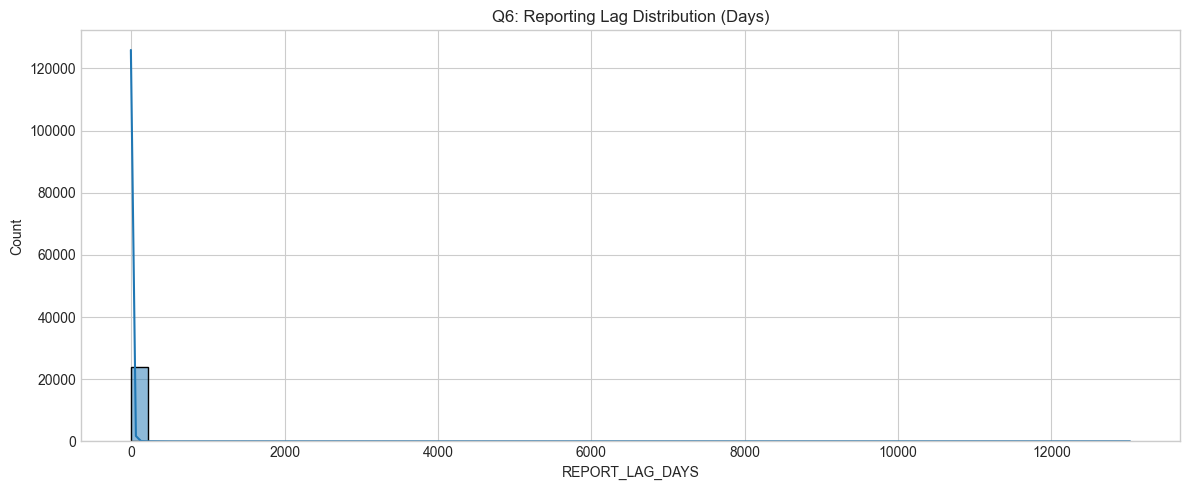

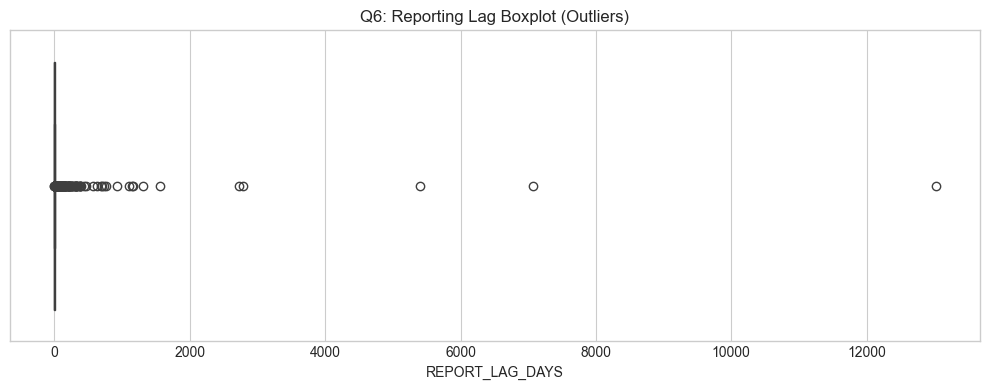

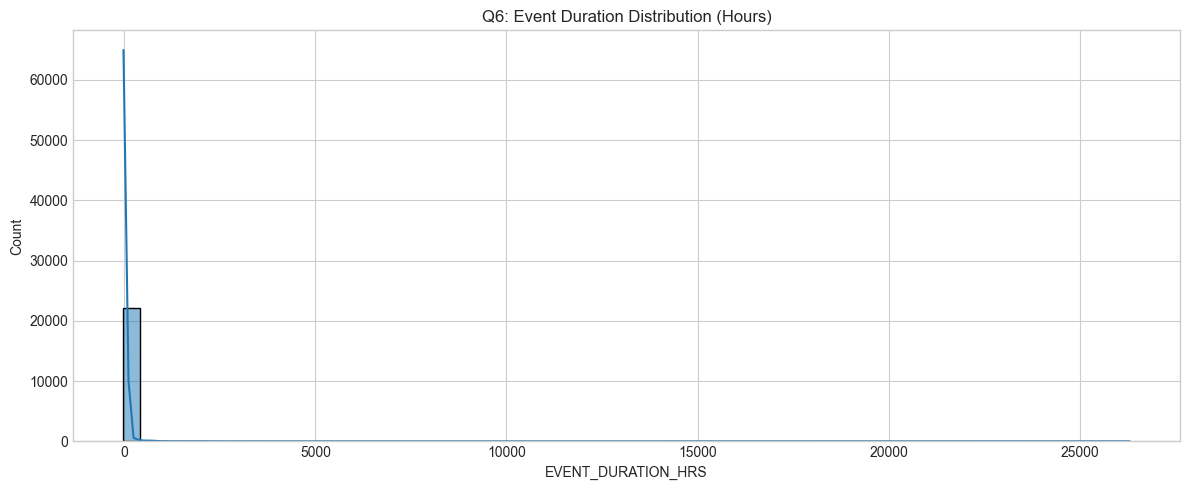

In [18]:
# Plot top suspicious flags
top_flags = flag_summary.head(10).copy()

plt.figure(figsize=(12, 6))
plt.barh(top_flags["Flag"][::-1], top_flags["Count"][::-1], edgecolor="black")
plt.title("Q6: Top Suspicious Flags (Count)")
plt.xlabel("Count")
plt.tight_layout()
plt.show()

# Reporting lag distribution
plt.figure(figsize=(12, 5))
sns.histplot(df["REPORT_LAG_DAYS"].dropna(), bins=60, kde=True)
plt.title("Q6: Reporting Lag Distribution (Days)")
plt.xlabel("REPORT_LAG_DAYS")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
sns.boxplot(x=df["REPORT_LAG_DAYS"])
plt.title("Q6: Reporting Lag Boxplot (Outliers)")
plt.xlabel("REPORT_LAG_DAYS")
plt.tight_layout()
plt.show()

# Duration distribution
plt.figure(figsize=(12, 5))
sns.histplot(df["EVENT_DURATION_HRS"].dropna(), bins=60, kde=True)
plt.title("Q6: Event Duration Distribution (Hours)")
plt.xlabel("EVENT_DURATION_HRS")
plt.tight_layout()
plt.show()




## Q7: Key Findings and Observations

Exploratory analysis revealed several noteworthy patterns in the crime incident data:

- **Time-of-day concentration**
  Incident volumes are not uniformly distributed throughout the day. Distinct peak periods are observed, suggesting a strong relationship between crime occurrence and daily human activity patterns.

- **Day-of-week variation**
  Certain days consistently show higher incident counts than others, indicating weekly behavioral trends rather than random occurrence.

- **Spatial concentration**
  A small number of wards account for a disproportionately large share of reported incidents, highlighting localized crime hotspots.

### Why These Findings Matter

These observations are important because:

- They support targeted allocation of public safety resources rather than uniform deployment.
- They provide insight into temporal and spatial patterns that can guide preventative strategies.
- They improve the interpretability and reliability of downstream analytical or predictive models.


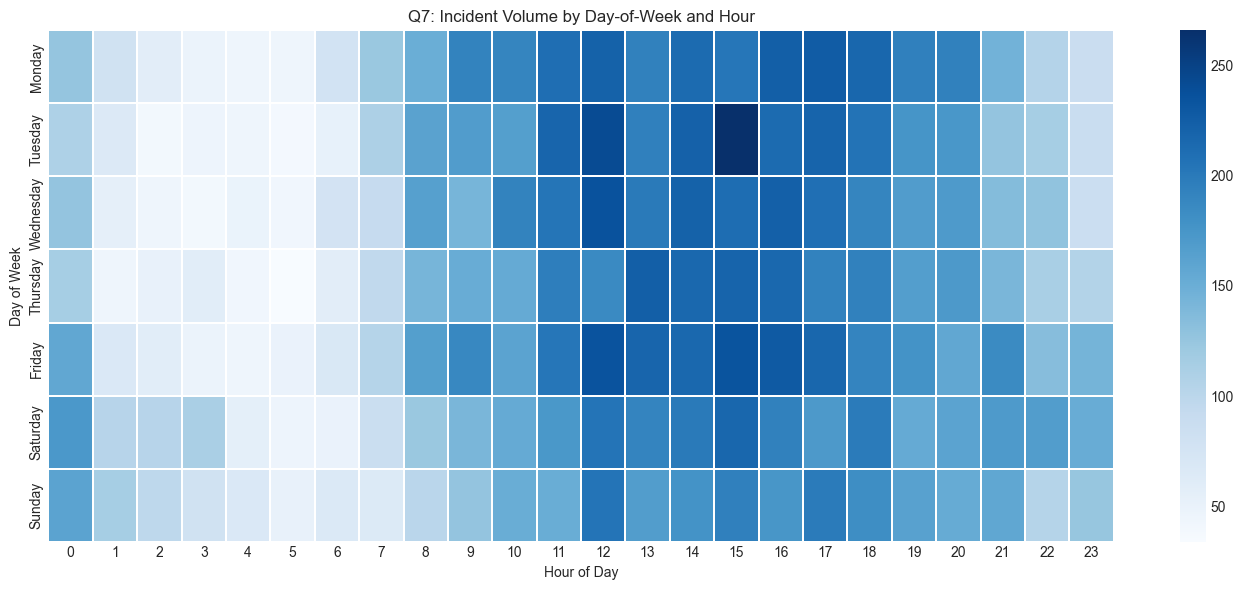

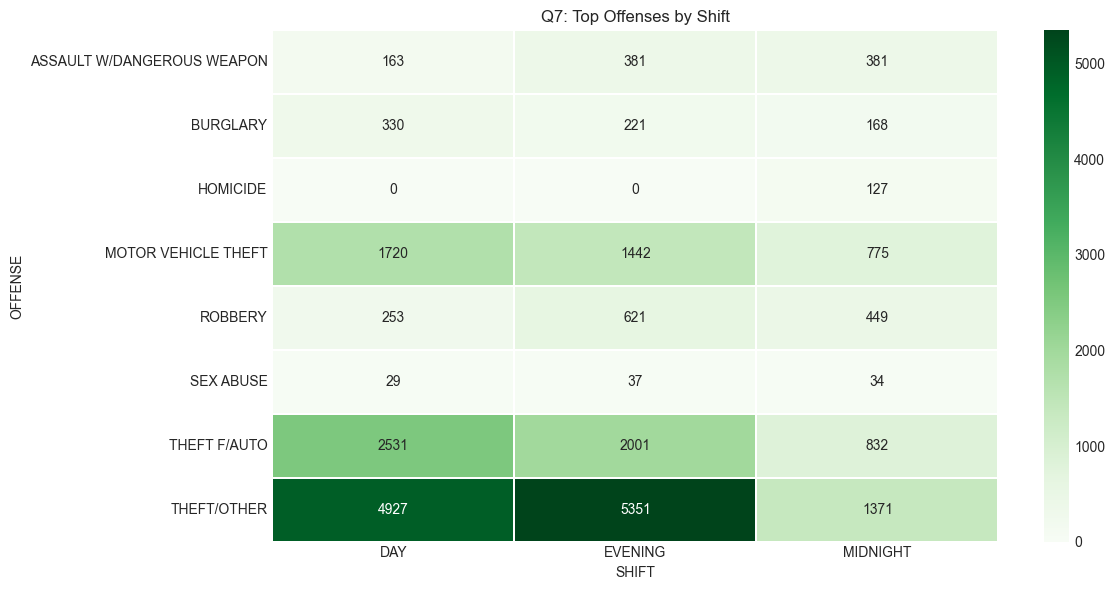

In [19]:
# Local time features (important for real patterns)
df["START_LOCAL"] = df["START_DATE"].dt.tz_convert("America/New_York")
df["HOUR"] = df["START_LOCAL"].dt.hour
df["DOW_NAME"] = df["START_LOCAL"].dt.day_name()

dow_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

# Day-of-week x Hour heatmap
heat = df.pivot_table(index="DOW_NAME", columns="HOUR", values=df.columns[0], aggfunc="count").reindex(dow_order)

plt.figure(figsize=(14, 6))
sns.heatmap(heat, cmap="Blues", linewidths=0.2)
plt.title("Q7: Incident Volume by Day-of-Week and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")
plt.tight_layout()
plt.show()

# Offense vs Shift (if SHIFT exists)
if "SHIFT" in df.columns and "OFFENSE" in df.columns:
    top_off = df["OFFENSE"].value_counts().head(8).index
    tmp = df[df["OFFENSE"].isin(top_off)]
    ct = pd.crosstab(tmp["OFFENSE"], tmp["SHIFT"])

    plt.figure(figsize=(12, 6))
    sns.heatmap(ct, annot=True, fmt="d", cmap="Greens", linewidths=0.3)
    plt.title("Q7: Top Offenses by Shift")
    plt.tight_layout()
    plt.show()


## Q8: Proposed Next Steps – Data Cleansing Strategy

Before performing advanced analysis or modeling, the following data cleansing steps are recommended:

1. **Scope filtering**
   - Restrict analysis to incidents occurring in the year 2025 to align with the dataset’s stated purpose.

2. **Temporal consistency checks**
   - Flag or remove records with negative reporting lag.
   - Remove records with negative event duration.
   - Review records with exceptionally long reporting delays for validity.

3. **Categorical data standardization**
   - Normalize categorical fields such as offense type, method, and shift by trimming whitespace and standardizing text.
   - Convert placeholder values (e.g., “Unknown”, empty strings) to null values.

4. **Geographic validation**
   - Validate latitude and longitude values to ensure they fall within the expected geographic region.
   - Flag or remove records with implausible coordinates.

5. **Duplicate handling**
   - Remove fully duplicated records.
   - For repeated incident identifiers, retain the most recent record based on the report date.

6. **Missing value strategy**
   - Preserve missing values for critical variables while optionally adding indicator flags.
   - Apply limited imputation only where logically justified.

This structured approach ensures data quality while minimizing the loss of valid information.


## Q9: Proposed Feature Engineering

To enhance analytical depth and model performance, the following feature engineering strategies are recommended:

### Temporal Features
- Hour of day
- Day of week
- Month and week number
- Weekend versus weekday indicator
- Seasonal categorization (Winter, Spring, Summer, Fall)

### Reporting Quality Features
- Reporting lag measured in days
- Reporting lag categorized into meaningful intervals (e.g., same-day, short delay, long delay)

### Spatial Features
- Ward, district, and PSA-based encodings
- Geographic binning or clustering when coordinate data is available

### Categorical Consolidation
- Grouping infrequent offense types into an “Other” category
- Standardizing and grouping crime methods to reduce category sparsity

These engineered features capture temporal, spatial, and behavioral dimensions of crime incidents and support more robust analysis.


---

# Week 2: Tree-Based Predictive Modeling (Part 2)

This section converts the descriptive crime incident dataset into a supervised machine learning problem and applies tree-based models:

- Decision Tree
- Random Forest
- Gradient Boosting Machine (GBM)

### Target Definition (Outcome)
A binary **HOTSPOT** label is created using aggregated incident counts across **Ward × Time** buckets.  
Buckets with incident counts above the 75th percentile (computed on training data only) are labeled as hotspots.

### Note on Scaling
Standardization/normalization is not applied because tree-based models are invariant to feature scaling (splits are based on thresholds, not distances).


In [20]:
import numpy as np
import pandas as pd

# -----------------------------
# Safety checks (expected cols)
# -----------------------------
required_cols = ["START_DATE", "REPORT_DAT", "WARD"]
missing_required = [c for c in required_cols if c not in df.columns]
if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}. Please verify column names in df.columns")

# -----------------------------
# Use local time for DC patterns
# -----------------------------
df_model_src = df.copy()
df_model_src = df_model_src.dropna(subset=["START_DATE"]).copy()

# Restrict to 2025 (consistent with Week-1 project scope)
df_model_src = df_model_src[df_model_src["START_DATE"].dt.year == 2025].copy()

df_model_src["START_LOCAL"] = df_model_src["START_DATE"].dt.tz_convert("America/New_York")

# Time features
df_model_src["MONTH"] = df_model_src["START_LOCAL"].dt.month
df_model_src["DOW"]   = df_model_src["START_LOCAL"].dt.dayofweek   # 0=Mon
df_model_src["HOUR"]  = df_model_src["START_LOCAL"].dt.hour
df_model_src["IS_WEEKEND"] = df_model_src["DOW"].isin([5,6]).astype(int)

# Ward cleaning
df_model_src["WARD_NUM"] = pd.to_numeric(df_model_src["WARD"], errors="coerce")
df_model_src = df_model_src[df_model_src["WARD_NUM"].between(1, 8)].copy()

# ---------------------------------------------
# Aggregate into Ward × Time buckets (features)
# ---------------------------------------------
# Keeping month and day-of-week helps the model learn seasonality and weekly patterns.
model_df = (
    df_model_src
    .groupby(["WARD_NUM", "MONTH", "DOW", "HOUR", "IS_WEEKEND"])
    .size()
    .reset_index(name="INCIDENT_COUNT")
)

print("Modeling table shape:", model_df.shape)
model_df.head()


Modeling table shape: (11152, 6)


,WARD_NUM,MONTH,DOW,HOUR,IS_WEEKEND,INCIDENT_COUNT
0,1,1,0,3,0,1
1,1,1,0,5,0,3
2,1,1,0,7,0,1
3,1,1,0,8,0,2
4,1,1,0,9,0,4


In [21]:
# -----------------------------------------
# Time-based split: Train (Jan–Sep), Test (Oct–Dec)
# -----------------------------------------
train_df = model_df[model_df["MONTH"] <= 9].copy()
test_df  = model_df[model_df["MONTH"] >= 10].copy()

print("Train rows:", len(train_df), "| Test rows:", len(test_df))

# -----------------------------------------
# Define HOTSPOT threshold from TRAIN ONLY
# -----------------------------------------
threshold = train_df["INCIDENT_COUNT"].quantile(0.75)  # top 25% = hotspot
train_df["HOTSPOT"] = (train_df["INCIDENT_COUNT"] >= threshold).astype(int)
test_df["HOTSPOT"]  = (test_df["INCIDENT_COUNT"]  >= threshold).astype(int)

Train rows: 8552 | Test rows: 2600


In [22]:
from sklearn.model_selection import train_test_split

feature_cols = ["WARD_NUM", "MONTH", "DOW", "HOUR", "IS_WEEKEND"]
X_train = train_df[feature_cols].copy()
y_train = train_df["HOTSPOT"].copy()

X_test  = test_df[feature_cols].copy()
y_test  = test_df["HOTSPOT"].copy()

# One-hot encoding for categorical-like numeric features (safe + interpretable)
X_train_enc = pd.get_dummies(X_train.astype(int), columns=["WARD_NUM", "MONTH", "DOW", "HOUR"], drop_first=False)
X_test_enc  = pd.get_dummies(X_test.astype(int),  columns=["WARD_NUM", "MONTH", "DOW", "HOUR"], drop_first=False)

# Align train/test columns
X_test_enc = X_test_enc.reindex(columns=X_train_enc.columns, fill_value=0)

print("Encoded shapes:", X_train_enc.shape, X_test_enc.shape)


Encoded shapes: (8552, 49) (2600, 49)


In [23]:
print("HOTSPOT threshold (train 75th percentile):", threshold)
print("Train HOTSPOT rate:", round(train_df["HOTSPOT"].mean(), 3))
print("Test  HOTSPOT rate:", round(test_df["HOTSPOT"].mean(), 3))
# Check class imbalance explicitly
print("Train positives (HOTSPOT=1):", (y_train == 1).sum())
print("Train negatives (HOTSPOT=0):", (y_train == 0).sum())
print("Test positives (HOTSPOT=1):", (y_test == 1).sum())
print("Test negatives (HOTSPOT=0):", (y_test == 0).sum())

HOTSPOT threshold (train 75th percentile): 3.0
Train HOTSPOT rate: 0.329
Test  HOTSPOT rate: 0.248
Train positives (HOTSPOT=1): 2813
Train negatives (HOTSPOT=0): 5739
Test positives (HOTSPOT=1): 645
Test negatives (HOTSPOT=0): 1955


In [24]:
# ===============================
# LightGBM Model Adapted to Existing Notebook Variables
# ===============================

# This code assumes the following already exist from your notebook:
# model_df, train_df, test_df
# feature_cols = ["WARD_NUM", "MONTH", "DOW", "HOUR", "IS_WEEKEND"]
# X_train_enc, X_test_enc, y_train, y_test

import time
import numpy as np
import matplotlib.pyplot as plt

from lightgbm import LGBMClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve, confusion_matrix
)

# -----------------------------------------
# Evaluation helper (same pattern as notebook)
# -----------------------------------------
def evaluate_lgbm(name, model, Xtr, ytr, Xte, yte):
    start = time.perf_counter()
    model.fit(Xtr, ytr)
    train_time = time.perf_counter() - start

    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]

    return {
        "Model": name,
        "Accuracy": accuracy_score(yte, pred),
        "Precision": precision_score(yte, pred),
        "Recall": recall_score(yte, pred),
        "F1": f1_score(yte, pred),
        "ROC_AUC": roc_auc_score(yte, proba),
        "Train_Time": train_time,
        "Pred": pred,
        "Proba": proba
    }

# -----------------------------------------
# Base LightGBM Model
# -----------------------------------------
lgbm_base = LGBMClassifier(
    objective="binary",
    random_state=42,
    class_weight="balanced",
    n_estimators=200
)

base_results = evaluate_lgbm(
    "LightGBM (Base)",
    lgbm_base,
    X_train_enc,
    y_train,
    X_test_enc,
    y_test
)

# -----------------------------------------
# Hyperparameter Tuning
# -----------------------------------------
param_grid = {
    "num_leaves": [31, 63],
    "learning_rate": [0.05, 0.1],
    "max_depth": [-1, 10],
    "min_child_samples": [20, 40],
    "lambda_l1": [0, 0.5],
    "lambda_l2": [0, 1.0]
}

gs = GridSearchCV(
    LGBMClassifier(
        objective="binary",
        random_state=42,
        class_weight="balanced",
        n_estimators=300
    ),
    param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1
)

start = time.perf_counter()
gs.fit(X_train_enc, y_train)
tune_time = time.perf_counter() - start

best_lgbm = gs.best_estimator_

print("Best LightGBM Parameters:\n", gs.best_params_)

# -----------------------------------------
# Evaluate Tuned Model
# -----------------------------------------
tuned_results = evaluate_lgbm(
    "LightGBM (Tuned)",
    best_lgbm,
    X_train_enc,
    y_train,
    X_test_enc,
    y_test
)

# -----------------------------------------
# Confusion Matrix
# -----------------------------------------
cm = confusion_matrix(y_test, tuned_results["Pred"])
print("Confusion Matrix:\n", cm)

# -----------------------------------------
# ROC Curve
# -----------------------------------------
fpr, tpr, _ = roc_curve(y_test, tuned_results["Proba"])
roc_auc = tuned_results["ROC_AUC"]

plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"LightGBM ROC Curve (AUC = {roc_auc:.2f})")
plt.show()

# -----------------------------------------
# Precision–Recall Curve
# -----------------------------------------
precision, recall, _ = precision_recall_curve(y_test, tuned_results["Proba"])

plt.figure()
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("LightGBM Precision–Recall Curve")
plt.show()

# -----------------------------------------
# Lorenz Curve
# -----------------------------------------
proba_sorted = np.sort(tuned_results["Proba"])
lorenz = np.cumsum(proba_sorted) / np.sum(proba_sorted)

plt.figure()
plt.plot(np.linspace(0, 1, len(lorenz)), lorenz)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("Cumulative Population Share")
plt.ylabel("Cumulative Hotspot Probability")
plt.title("LightGBM Lorenz Curve")
plt.show()

# -----------------------------------------
# Summary for model comparison table
# -----------------------------------------
print("\nBase Model Metrics:")
for k in ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]:
    print(f"{k}: {base_results[k]:.3f}")

print("\nTuned Model Metrics:")
for k in ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]:
    print(f"{k}: {tuned_results[k]:.3f}")


OSError: dlopen(/opt/miniconda3/lib/python3.13/site-packages/lightgbm/lib/lib_lightgbm.dylib, 0x0006): Library not loaded: @rpath/libomp.dylib
  Referenced from: <D44045CD-B874-3A27-9A61-F131D99AACE4> /opt/miniconda3/lib/python3.13/site-packages/lightgbm/lib/lib_lightgbm.dylib
  Reason: tried: '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/local/lib/libomp/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/local/lib/libomp/libomp.dylib' (no such file), '/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/opt/libomp/lib/libomp.dylib' (no such file), '/opt/local/lib/libomp/libomp.dylib' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/local/lib/libomp/libomp.dylib' (no such file), '/opt/miniconda3/lib/python3.13/lib-dynload/../../libomp.dylib' (no such file), '/opt/miniconda3/bin/../lib/l

In [ ]:
# =========================
# XGBoost Model 
# =========================
import time
import numpy as np

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Try importing XGBoost
try:
    from xgboost import XGBClassifier
except ImportError as e:
    raise ImportError(
        "xgboost is not installed in this environment.\n"
        "If you're using Colab, run: !pip install xgboost\n"
        "Then restart runtime and run again."
    )

def eval_binary_classifier(name, model, Xtr, ytr, Xte, yte):
    start = time.perf_counter()
    model.fit(Xtr, ytr)
    train_time = time.perf_counter() - start

    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1] if hasattr(model, "predict_proba") else None

    return {
        "Model": name,
        "Accuracy": accuracy_score(yte, pred),
        "Precision": precision_score(yte, pred, zero_division=0),
        "Recall": recall_score(yte, pred, zero_division=0),
        "F1": f1_score(yte, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(yte, proba) if proba is not None else np.nan,
        "Train_Time_sec": train_time,
        "Fitted_Model": model
    }
# Handle class imbalance for XGBoost
pos = (y_train == 1).sum()
neg = (y_train == 0).sum()
scale_pos_weight = neg / pos
# Baseline XGBoost (Week-2: light, not over-tuned)
xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.9,
    colsample_bytree=0.9,
    scale_pos_weight=scale_pos_weight,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    eval_metric="logloss"
)

xgb_result = eval_binary_classifier("XGBoost (Baseline)", xgb, X_train_enc, y_train, X_test_enc, y_test)

# Show results as a row
pd.DataFrame([{k:v for k,v in xgb_result.items() if k != "Fitted_Model"}])


## Models and Evaluation

The following tree-based models are trained and compared:

- **Decision Tree**: simple and interpretable, but can overfit.
- **Random Forest**: reduces overfitting using bagging and feature randomness.
- **Gradient Boosting (GBM)**: sequentially improves weak learners, often strong performance with limited tuning.

### Metrics reported
- Accuracy
- Precision / Recall / F1
- ROC-AUC (when probabilities are available)
- Training runtime (seconds)


In [ ]:
import time
import numpy as np

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

def evaluate_model(name, model, Xtr, ytr, Xte, yte):
    start = time.perf_counter()
    model.fit(Xtr, ytr)
    train_time = time.perf_counter() - start

    pred = model.predict(Xte)

    # Probabilities (for ROC-AUC)
    proba = None
    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(Xte)[:, 1]

    result = {
        "Model": name,
        "Accuracy": accuracy_score(yte, pred),
        "Precision": precision_score(yte, pred, zero_division=0),
        "Recall": recall_score(yte, pred, zero_division=0),
        "F1": f1_score(yte, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(yte, proba) if proba is not None else np.nan,
        "Train_Time_sec": train_time,
        "Fitted_Model": model
    }
    return result

# Week-2 baseline models (light settings)
dt  = DecisionTreeClassifier(random_state=42, max_depth=6, min_samples_leaf=5)
rf  = RandomForestClassifier(random_state=42, n_estimators=300, n_jobs=-1)
gbm = GradientBoostingClassifier(random_state=42)

results = []
results.append(evaluate_model("Decision Tree", dt, X_train_enc, y_train, X_test_enc, y_test))
results.append(evaluate_model("Random Forest", rf, X_train_enc, y_train, X_test_enc, y_test))
results.append(evaluate_model("GBM (GradientBoosting)", gbm, X_train_enc, y_train, X_test_enc, y_test))
results.append(xgb_result)

compare_df = pd.DataFrame([{k:v for k,v in r.items() if k != "Fitted_Model"} for r in results])
compare_df.sort_values("F1", ascending=False)

compare_df = pd.DataFrame([{k:v for k,v in r.items() if k != "Fitted_Model"} for r in results])
compare_df.sort_values("F1", ascending=False)


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

for r in results:
    model = r["Fitted_Model"]
    pred = model.predict(X_test_enc)
    cm = confusion_matrix(y_test, pred)

    plt.figure(figsize=(4,4))
    plt.imshow(cm)
    plt.title(f"Confusion Matrix: {r['Model']}")
    plt.xticks([0,1], ["Not Hotspot", "Hotspot"])
    plt.yticks([0,1], ["Not Hotspot", "Hotspot"])
    for i in range(2):
        for j in range(2):
            plt.text(j, i, cm[i,j], ha="center", va="center", fontsize=12)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()


In [ ]:
feature_names = X_train_enc.columns

def plot_feature_importance(model, title, top_n=20):
    if not hasattr(model, "feature_importances_"):
        print(f"{title}: feature_importances_ not available.")
        return

    imp = pd.Series(model.feature_importances_, index=feature_names).sort_values(ascending=False).head(top_n)

    plt.figure(figsize=(10, 6))
    plt.barh(imp.index[::-1], imp.values[::-1])
    plt.title(title)
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()

plot_feature_importance(results[0]["Fitted_Model"], "Feature Importance — Decision Tree")
plot_feature_importance(results[1]["Fitted_Model"], "Feature Importance — Random Forest")
plot_feature_importance(results[2]["Fitted_Model"], "Feature Importance — GBM (GradientBoosting)")
plot_feature_importance(xgb_result["Fitted_Model"], "Feature Importance — XGBoost")


## Hyperparameter Tuning (Light Optimization)

To satisfy model optimization requirements at Week-2 level, a small parameter grid is used with cross-validation:

- Decision Tree: max_depth, min_samples_leaf
- Random Forest: n_estimators, max_depth, min_samples_leaf
- GBM: n_estimators, learning_rate, max_depth

The goal is to demonstrate tuning methodology without excessive computation.


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

def tune_model(name, model, param_grid, Xtr, ytr, Xte, yte):
    start = time.perf_counter()
    gs = GridSearchCV(model, param_grid, scoring="f1", cv=3, n_jobs=-1)
    gs.fit(Xtr, ytr)
    tune_time = time.perf_counter() - start

    best = gs.best_estimator_
    pred = best.predict(Xte)
    proba = best.predict_proba(Xte)[:, 1] if hasattr(best, "predict_proba") else None

    return {
        "Model": f"{name} (Tuned)",
        "Best_Params": gs.best_params_,
        "Accuracy": accuracy_score(yte, pred),
        "Precision": precision_score(yte, pred, zero_division=0),
        "Recall": recall_score(yte, pred, zero_division=0),
        "F1": f1_score(yte, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(yte, proba) if proba is not None else np.nan,
        "Tuning_Time_sec": tune_time,
        "Fitted_Model": best
    }

dt_grid = {
    "max_depth": [3, 5, 7, None],
    "min_samples_leaf": [1, 5, 10]
}

rf_grid = {
    "n_estimators": [200, 400],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 5]
}

gbm_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3]
}
xgb_grid = {
    "n_estimators": [200, 400],
    "max_depth": [3, 5],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

xgb_base = XGBClassifier(
    random_state=42,
    n_jobs=-1,
    eval_metric="logloss"
)


tuned_results = []
tuned_results.append(tune_model("Decision Tree", DecisionTreeClassifier(random_state=42), dt_grid, X_train_enc, y_train, X_test_enc, y_test))
tuned_results.append(tune_model("Random Forest", RandomForestClassifier(random_state=42, n_jobs=-1), rf_grid, X_train_enc, y_train, X_test_enc, y_test))
tuned_results.append(tune_model("GBM", GradientBoostingClassifier(random_state=42), gbm_grid, X_train_enc, y_train, X_test_enc, y_test))
tuned_results.append(tune_model("XGBoost",xgb_base,xgb_grid,X_train_enc,y_train,X_test_enc,y_test))
tuned_compare_df = pd.DataFrame([{k:v for k,v in r.items() if k != "Fitted_Model"} for r in tuned_results])
tuned_compare_df.sort_values("F1", ascending=False)


In [ ]:
# Pick best tuned model by F1
best_tuned = max(tuned_results, key=lambda x: x["F1"])
best_model = best_tuned["Fitted_Model"]

print("Best tuned model:", best_tuned["Model"])
print("Best parameters:", best_tuned["Best_Params"])

plot_feature_importance(best_model, f"Feature Importance — {best_tuned['Model']}", top_n=25)
